In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Load dataset (pastikan file AB_NYC_2019.csv sudah di-upload ke Colab)
df = pd.read_csv('AB_NYC_2019.csv')

print("Informasi Dataset:")
print(df.info())
print("\nJumlah Missing Values:")
print(df.isnull().sum())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review  

In [2]:
# 1. Mengisi missing values pada reviews_per_month dengan 0
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# 2. Menghapus data duplikat jika ada
df = df.drop_duplicates()

# 3. Feature Engineering: Kategori Harga (Price Category)
def categorize_price(price):
    if price <= 75:
        return 'Budget (<= $75)'
    elif price <= 150:
        return 'Moderate ($76-$150)'
    elif price <= 300:
        return 'Expensive ($151-$300)'
    else:
        return 'Luxury (> $300)'

df['price_category'] = df['price'].apply(categorize_price)

# 4. Feature Engineering: Kategori Ketersediaan (Availability Group)
def categorize_availability(days):
    if days == 0:
        return 'Not Available (0 days)'
    elif days <= 100:
        return 'Low (1-100 days)'
    elif days <= 250:
        return 'Medium (101-250 days)'
    else:
        return 'High (> 250 days)'

df['availability_group'] = df['availability_365'].apply(categorize_availability)

print("Data cleaning dan feature engineering berhasil diset!")
print(df[['name', 'price', 'price_category', 'availability_group']].head(3))

Data cleaning dan feature engineering berhasil diset!
                                  name  price         price_category  \
0   Clean & quiet apt home by the park    149    Moderate ($76-$150)   
1                Skylit Midtown Castle    225  Expensive ($151-$300)   
2  THE VILLAGE OF HARLEM....NEW YORK !    150    Moderate ($76-$150)   

  availability_group  
0  High (> 250 days)  
1  High (> 250 days)  
2  High (> 250 days)  


/tmp/ipykernel_1121/246656630.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='room_type', palette='Set2', order=df['room_type'].value_counts().index)


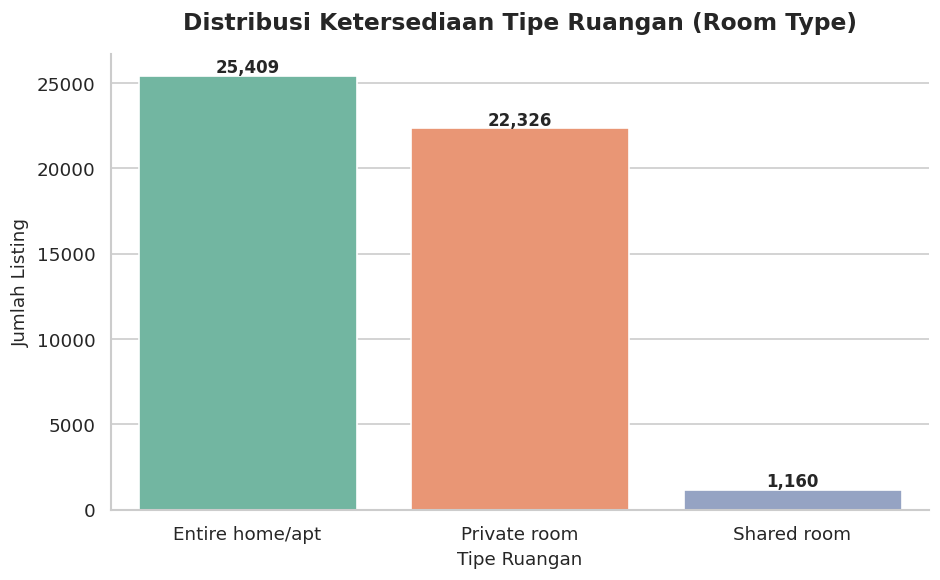

In [4]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='room_type', palette='Set2', order=df['room_type'].value_counts().index)

plt.title('Distribusi Ketersediaan Tipe Ruangan (Room Type)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tipe Ruangan', fontsize=11)
plt.ylabel('Jumlah Listing', fontsize=11)

# Menambahkan label angka di atas batang
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f'{height:,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 5), textcoords='offset points',
                fontsize=10, fontweight='bold')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1121/3830391632.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=avg_price_geo, y='neighbourhood_group', x='price', palette='viridis')


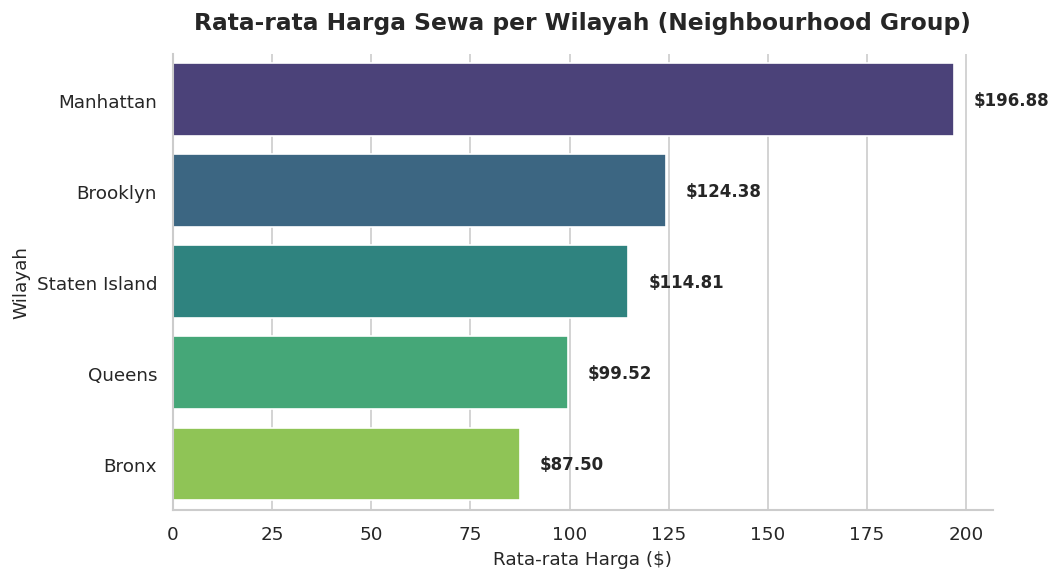

In [5]:
plt.figure(figsize=(9, 5))
avg_price_geo = df.groupby('neighbourhood_group')['price'].mean().reset_index().sort_values(by='price', ascending=False)

ax = sns.barplot(data=avg_price_geo, y='neighbourhood_group', x='price', palette='viridis')

plt.title('Rata-rata Harga Sewa per Wilayah (Neighbourhood Group)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rata-rata Harga ($)', fontsize=11)
plt.ylabel('Wilayah', fontsize=11)

# Menambahkan label nilai di ujung batang
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'${width:.2f}', (width + 5, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=10, fontweight='bold')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

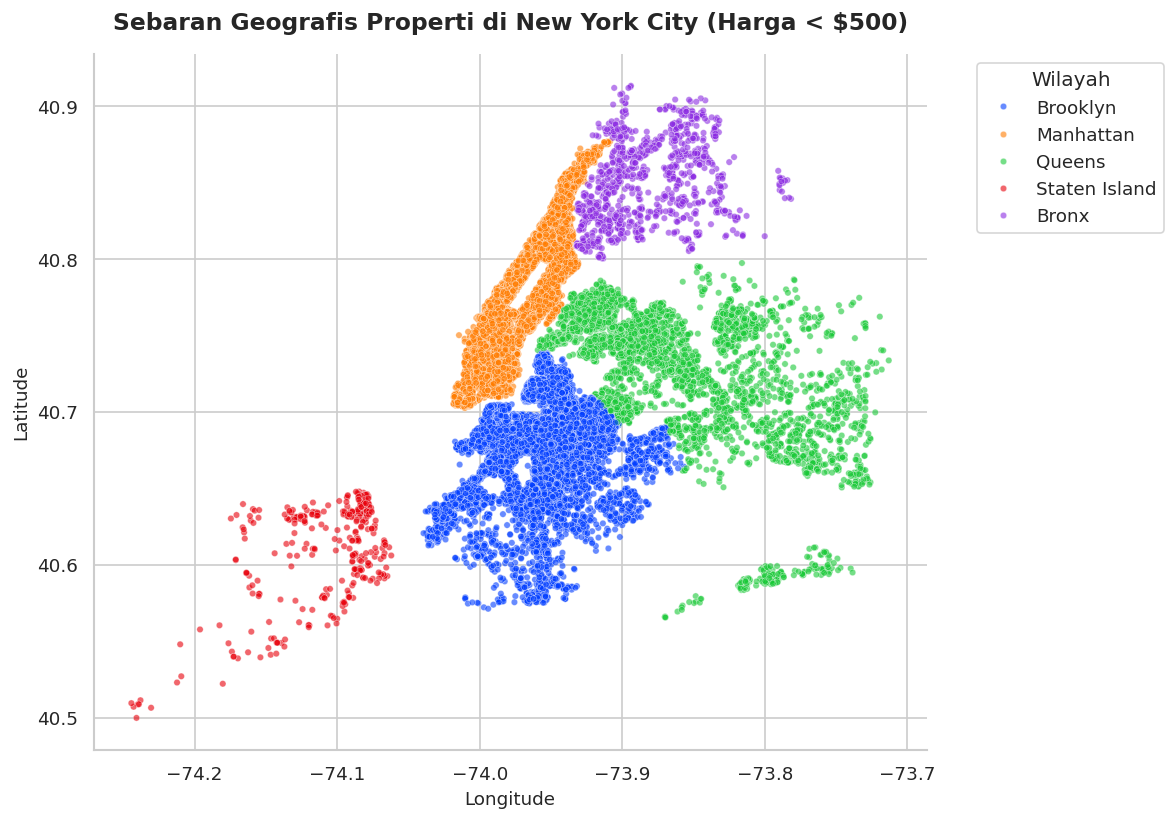

In [6]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df[df['price'] < 500], x='longitude', y='latitude', hue='neighbourhood_group',
                palette='bright', alpha=0.6, s=15)

plt.title('Sebaran Geografis Properti di New York City (Harga < $500)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=11)
plt.ylabel('Latitude', fontsize=11)
plt.legend(title='Wilayah', bbox_to_anchor=(1.05, 1), loc='upper left')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1121/500323136.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['price'] < 600], x='neighbourhood_group', y='price', palette='pastel')


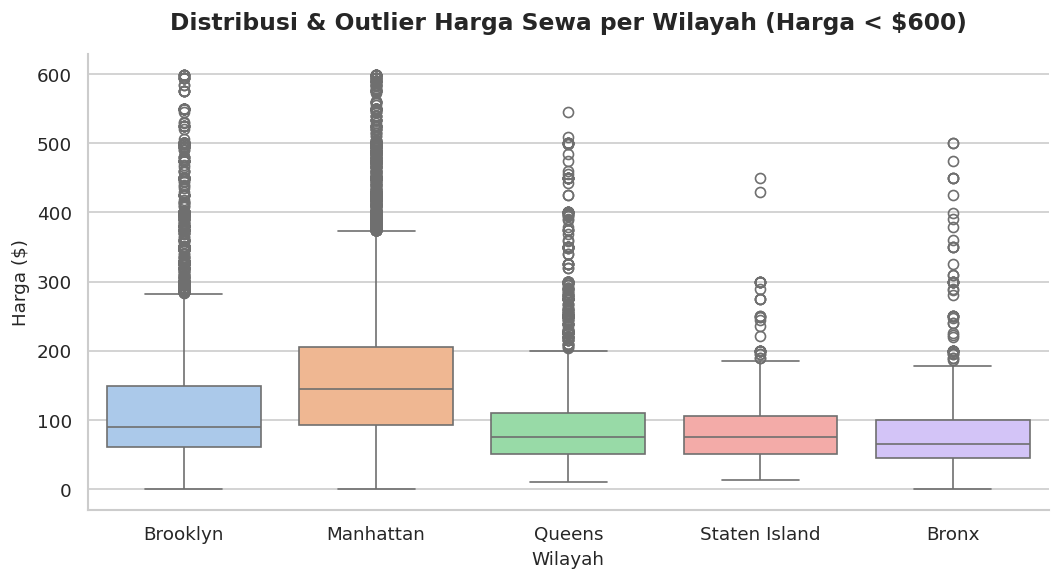

In [7]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[df['price'] < 600], x='neighbourhood_group', y='price', palette='pastel')

plt.title('Distribusi & Outlier Harga Sewa per Wilayah (Harga < $600)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Wilayah', fontsize=11)
plt.ylabel('Harga ($)', fontsize=11)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

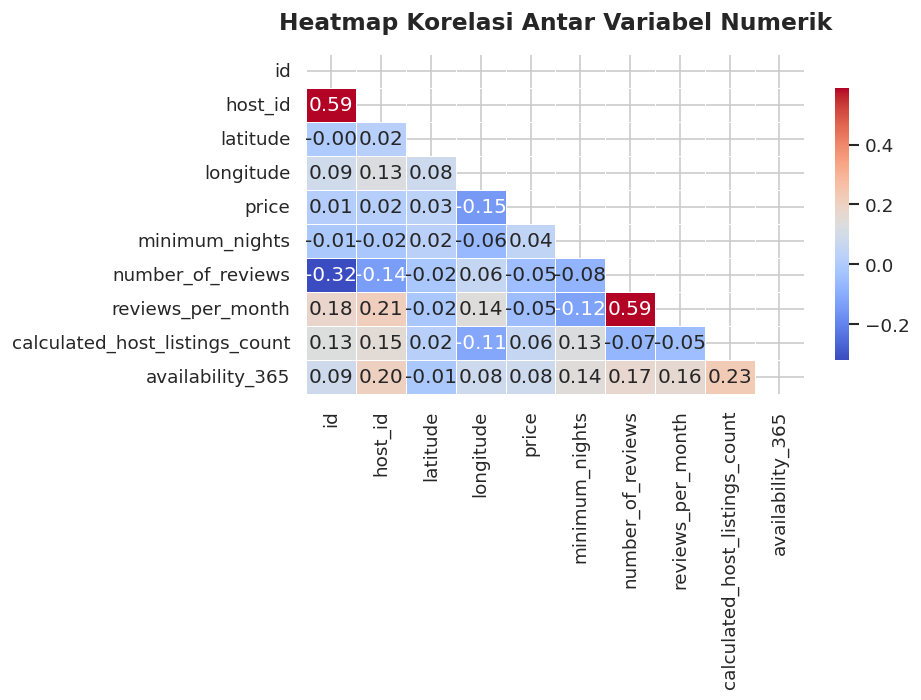

In [8]:
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, linewidths=0.5, cbar_kws={'shrink': 0.8})

plt.title('Heatmap Korelasi Antar Variabel Numerik', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

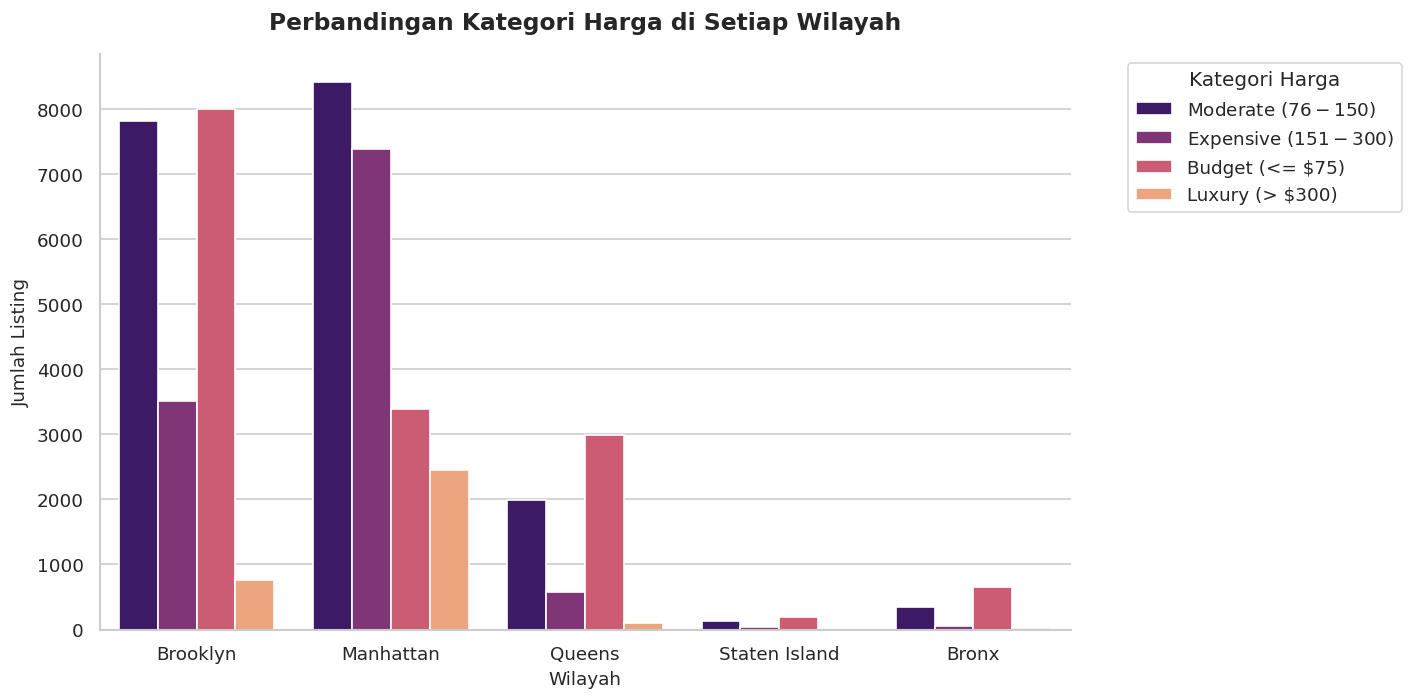

In [9]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='neighbourhood_group', hue='price_category', palette='magma')

plt.title('Perbandingan Kategori Harga di Setiap Wilayah', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Wilayah', fontsize=11)
plt.ylabel('Jumlah Listing', fontsize=11)
plt.legend(title='Kategori Harga', bbox_to_anchor=(1.05, 1), loc='upper left')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1121/3414612219.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='room_type', palette='Set2', order=df['room_type'].value_counts().index, ax=ax1)
/tmp/ipykernel_1121/3414612219.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_price_geo, y='neighbourhood_group', x='price', palette='viridis', ax=ax2)
/tmp/ipykernel_1121/3414612219.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['price'] < 600], x='neighbourhood_group', y='price', palette='pastel', ax=ax4)


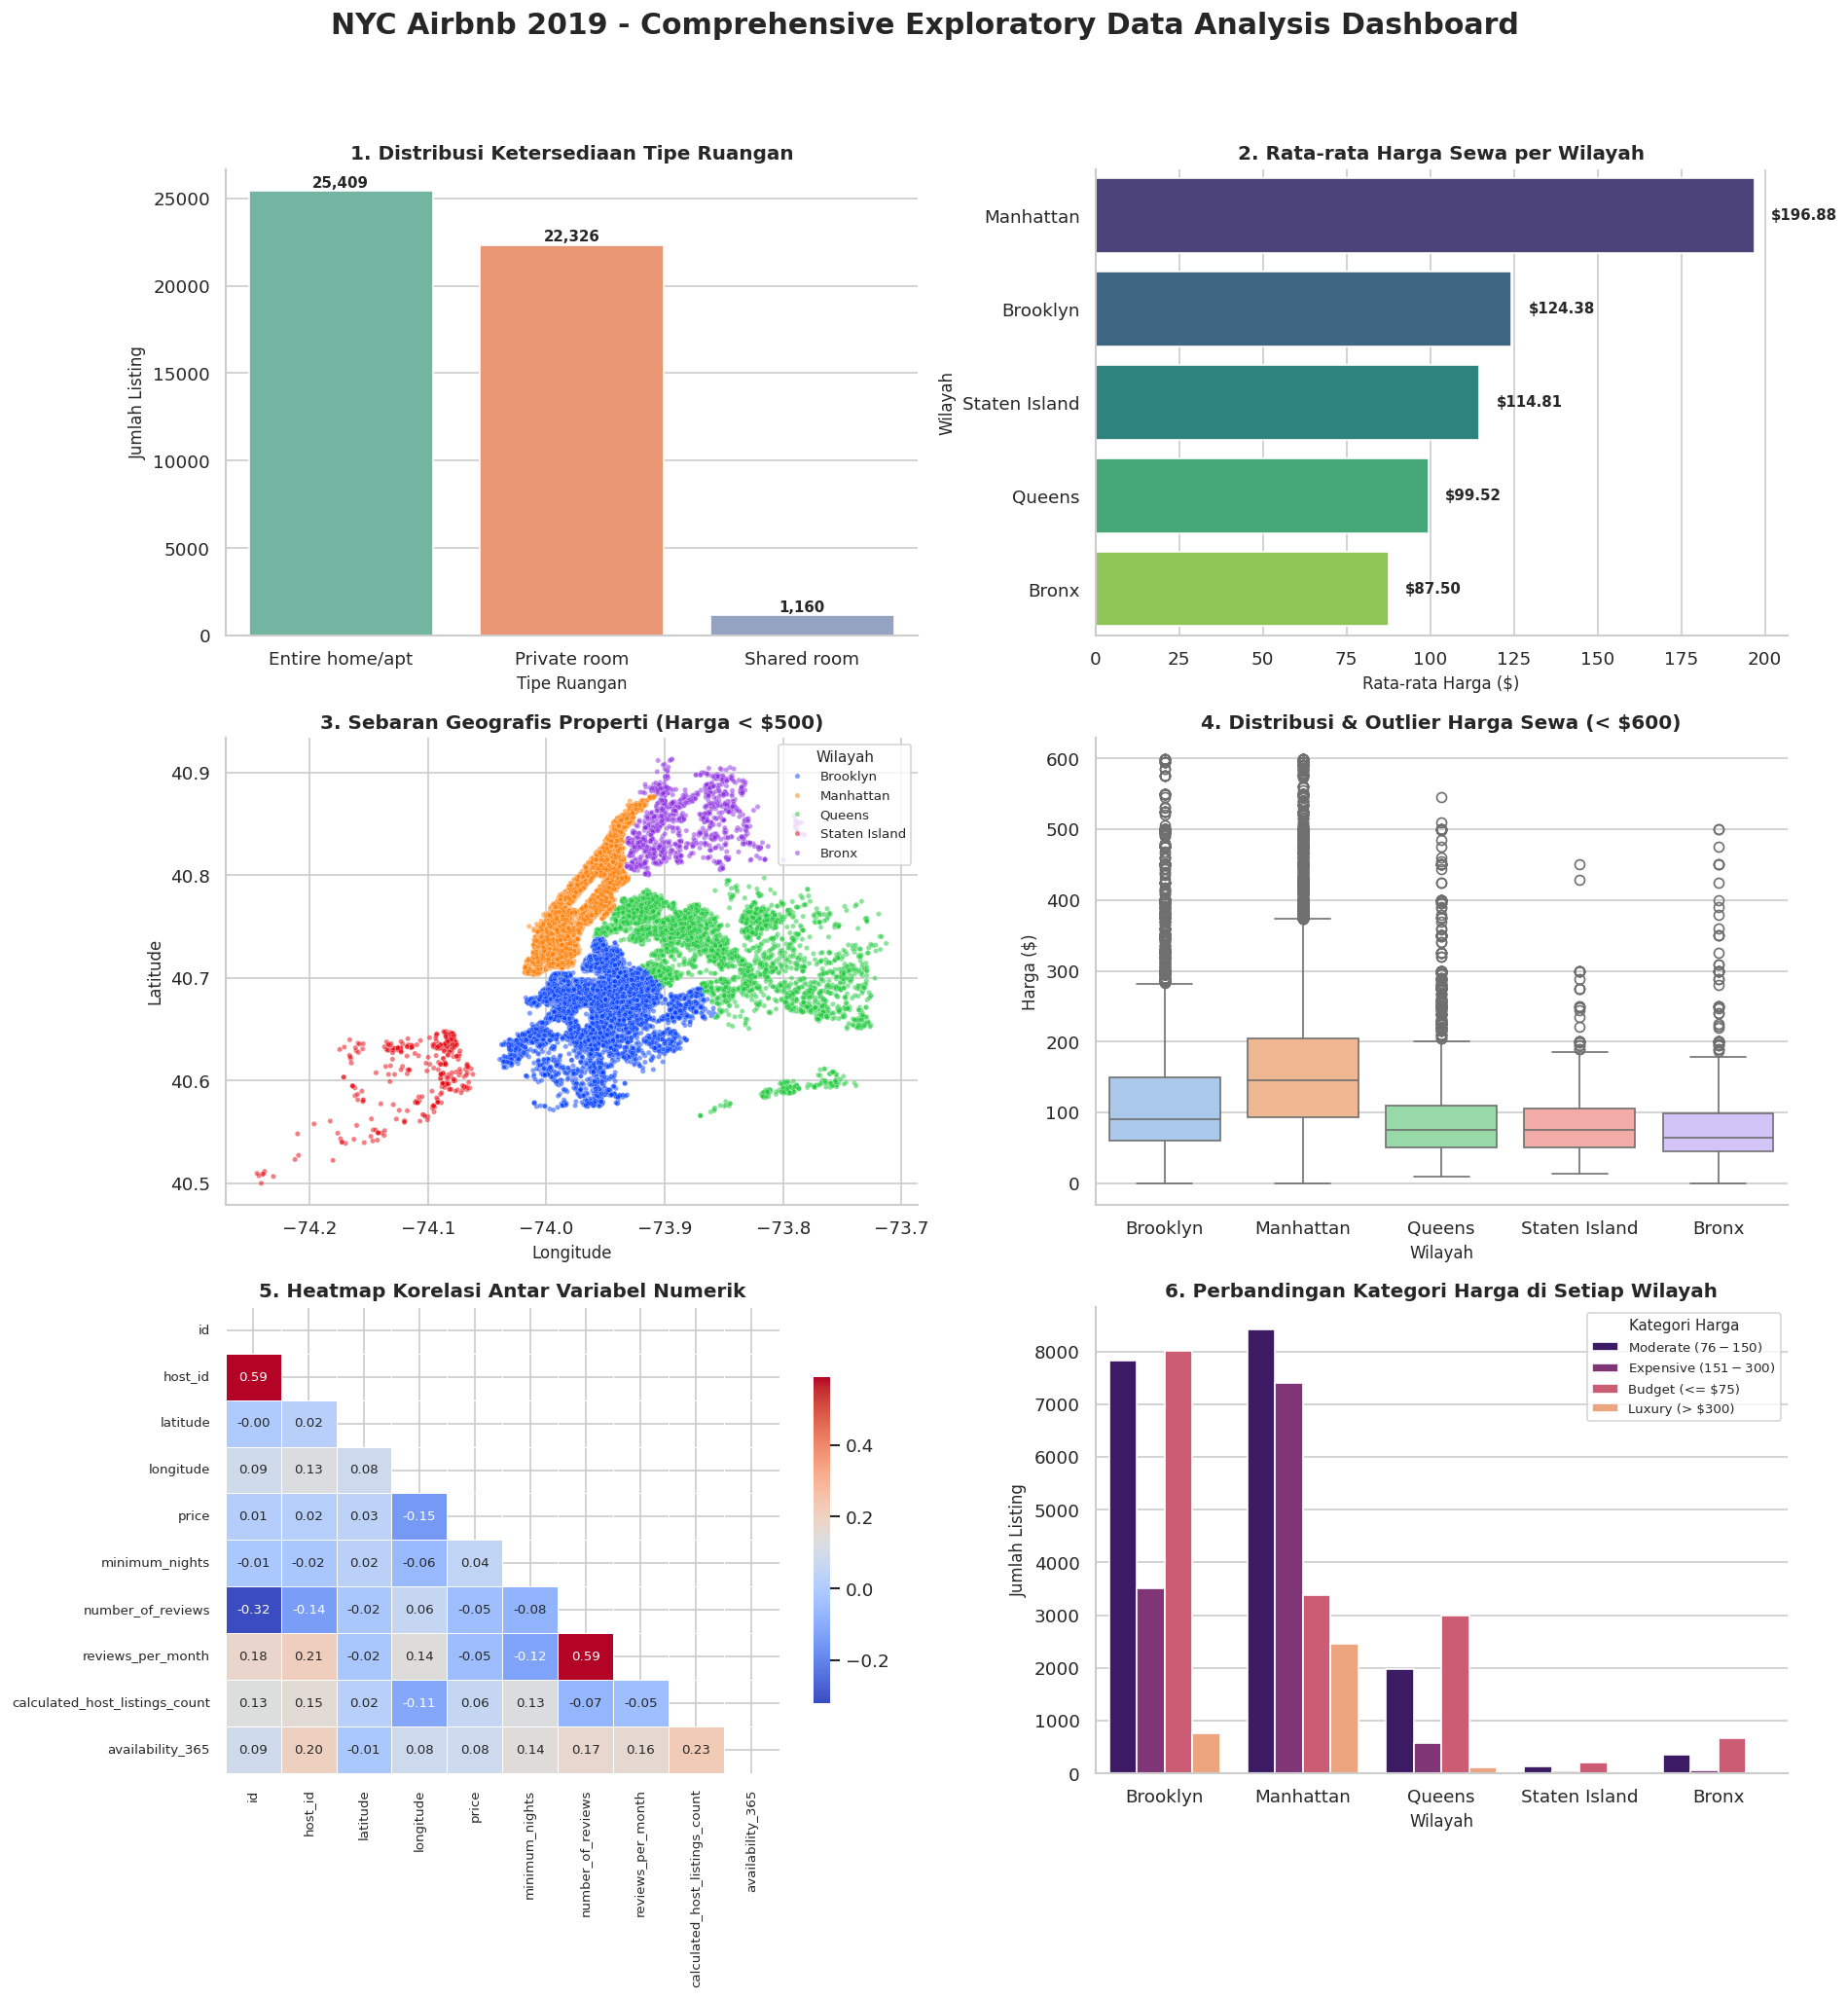

In [10]:
# ==========================================
# DASHBOARD UTAMA: MENYATUKAN SELURUH 6 GRAFIK DALAM 1 TAMPILAN
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# 1. Load dataset (pastikan file AB_NYC_2019.csv sudah di-upload)
df = pd.read_csv('AB_NYC_2019.csv')

# 2. Data Cleaning & Feature Engineering singkat
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
df = df.drop_duplicates()

def categorize_price(price):
    if price <= 75:
        return 'Budget (<= $75)'
    elif price <= 150:
        return 'Moderate ($76-$150)'
    elif price <= 300:
        return 'Expensive ($151-$300)'
    else:
        return 'Luxury (> $300)'

df['price_category'] = df['price'].apply(categorize_price)

# 3. Membuat Canvas Dashboard (3 Baris x 2 Kolom)
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('NYC Airbnb 2019 - Comprehensive Exploratory Data Analysis Dashboard', fontsize=18, fontweight='bold', y=0.98)

# --- Grafik 1: Distribusi Tipe Ruangan ---
ax1 = axes[0, 0]
sns.countplot(data=df, x='room_type', palette='Set2', order=df['room_type'].value_counts().index, ax=ax1)
ax1.set_title('1. Distribusi Ketersediaan Tipe Ruangan', fontsize=12, fontweight='bold')
ax1.set_xlabel('Tipe Ruangan', fontsize=10)
ax1.set_ylabel('Jumlah Listing', fontsize=10)
for p in ax1.patches:
    height = int(p.get_height())
    ax1.annotate(f'{height:,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9, fontweight='bold')
sns.despine(ax=ax1, top=True, right=True)

# --- Grafik 2: Rata-rata Harga per Wilayah ---
ax2 = axes[0, 1]
avg_price_geo = df.groupby('neighbourhood_group')['price'].mean().reset_index().sort_values(by='price', ascending=False)
sns.barplot(data=avg_price_geo, y='neighbourhood_group', x='price', palette='viridis', ax=ax2)
ax2.set_title('2. Rata-rata Harga Sewa per Wilayah', fontsize=12, fontweight='bold')
ax2.set_xlabel('Rata-rata Harga ($)', fontsize=10)
ax2.set_ylabel('Wilayah', fontsize=10)
for p in ax2.patches:
    width = p.get_width()
    ax2.annotate(f'${width:.2f}', (width + 5, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=9, fontweight='bold')
sns.despine(ax=ax2, top=True, right=True)

# --- Grafik 3: Sebaran Spasial (Latitude vs Longitude) ---
ax3 = axes[1, 0]
sns.scatterplot(data=df[df['price'] < 500], x='longitude', y='latitude', hue='neighbourhood_group',
                palette='bright', alpha=0.5, s=10, ax=ax3)
ax3.set_title('3. Sebaran Geografis Properti (Harga < $500)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Longitude', fontsize=10)
ax3.set_ylabel('Latitude', fontsize=10)
ax3.legend(title='Wilayah', fontsize=8, title_fontsize=9, loc='upper right')
sns.despine(ax=ax3, top=True, right=True)

# --- Grafik 4: Analisis Outlier Harga (Boxplot) ---
ax4 = axes[1, 1]
sns.boxplot(data=df[df['price'] < 600], x='neighbourhood_group', y='price', palette='pastel', ax=ax4)
ax4.set_title('4. Distribusi & Outlier Harga Sewa (< $600)', fontsize=12, fontweight='bold')
ax4.set_xlabel('Wilayah', fontsize=10)
ax4.set_ylabel('Harga ($)', fontsize=10)
sns.despine(ax=ax4, top=True, right=True)

# --- Grafik 5: Heatmap Korelasi ---
ax5 = axes[2, 0]
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, linewidths=0.5, cbar_kws={'shrink': 0.7}, ax=ax5, annot_kws={'size': 8})
ax5.set_title('5. Heatmap Korelasi Antar Variabel Numerik', fontsize=12, fontweight='bold')
ax5.tick_params(axis='both', labelsize=8)

# --- Grafik 6: Kategori Harga per Wilayah ---
ax6 = axes[2, 1]
sns.countplot(data=df, x='neighbourhood_group', hue='price_category', palette='magma', ax=ax6)
ax6.set_title('6. Perbandingan Kategori Harga di Setiap Wilayah', fontsize=12, fontweight='bold')
ax6.set_xlabel('Wilayah', fontsize=10)
ax6.set_ylabel('Jumlah Listing', fontsize=10)
ax6.legend(title='Kategori Harga', fontsize=8, title_fontsize=9, loc='upper right')
sns.despine(ax=ax6, top=True, right=True)

# Mengatur tata letak agar rapi dan tidak saling tumpang tindih
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()